In [1]:
# Load the data
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

In [2]:
# Load cleaned training data
train_clean = pd.read_csv("cleaned_train.csv")
WAPS = [c for c in train_clean.columns if c.startswith("WAP")]

print(train_clean.shape, len(WAPS))

(19227, 475) 465


In [3]:
# Create groups
groups = (train_clean["BUILDINGID"].astype(str) + "_" +
          train_clean["FLOOR"].astype(str) + "_" +
          train_clean["SPACEID"].astype(str))

In [4]:
# Internal split
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
tr_idx, iv_idx = next(splitter.split(train_clean, groups=groups))

itrain = train_clean.iloc[tr_idx].reset_index(drop=True)
ival = train_clean.iloc[iv_idx].reset_index(drop=True)

print(len(itrain), len(ival))

15509 3718


In [5]:
# Load test files
te_dbm = pd.read_csv("validation_wifi_dbm.csv")
te_mask = pd.read_csv("validation_wifi_mask.csv")
te_lab = pd.read_csv("validation_labels.csv")

print(te_dbm.shape, te_mask.shape, te_lab.shape)
print(list(te_dbm.columns) == WAPS)

(1111, 465) (1111, 465) (1111, 4)
True


In [7]:
# Test metadata
original_test = pd.read_csv("validationData.csv")

te_meta = pd.DataFrame({
    "ROW_ID": np.arange(len(original_test)),
    "USERID": original_test["USERID"],
    "PHONEID": original_test["PHONEID"],
})

print(te_meta.shape)

(1111, 3)


In [8]:
# Encoding function
def encode(df):
    raw = df[WAPS]
    dbm = raw.replace(100, -110)
    mask = (raw != 100).astype(int)
    return dbm, mask

In [9]:
# Encode training data
tr_dbm, tr_mask = encode(itrain)
iv_dbm, iv_mask = encode(ival)

print(tr_dbm.shape, iv_dbm.shape)
print(tr_dbm.max().max(), tr_dbm.min().min())

(15509, 465) (3718, 465)
0 -110


In [10]:
# Targets
y_tr = itrain["BUILDINGID"]
y_iv = ival["BUILDINGID"]

print(y_tr.value_counts().sort_index().tolist())
print(y_iv.value_counts().sort_index().tolist())

[4173, 3863, 7473]
[1072, 1041, 1605]


# Engineered features

In [11]:
# Feature function
def make_features(dbm, mask):
    d = dbm.to_numpy(dtype=float)
    m = mask.to_numpy().astype(bool)
    obs = np.where(m, d, np.nan)

    return pd.DataFrame({
        "n_heard": m.sum(axis=1),
        "max_rssi": np.nanmax(obs, axis=1),
        "mean_rssi": np.nanmean(obs, axis=1),
        "std_rssi": np.nanstd(obs, axis=1),
        "n_strong": (obs > -70).sum(axis=1),
        "top1_ap": d.argmax(axis=1),
    }, index=dbm.index)

In [12]:
# Build features
tr_feat = make_features(tr_dbm, tr_mask)
iv_feat = make_features(iv_dbm, iv_mask)
te_feat = make_features(te_dbm, te_mask)

print(tr_feat.shape, iv_feat.shape, te_feat.shape)

(15509, 6) (3718, 6) (1111, 6)


In [13]:
# Check for missing values
print(tr_feat.isna().sum().sum(),
      iv_feat.isna().sum().sum(),
      te_feat.isna().sum().sum())

0 0 0


In [14]:
# Check value ranges
tr_feat.describe().round(1).loc[["mean", "min", "max"]]

,n_heard,max_rssi,mean_rssi,std_rssi,n_strong,top1_ap
mean,17.9,-57.1,-78.9,10.6,3.7,137.5
min,1.0,-96.0,-96.2,0.0,0.0,3.0
max,51.0,0.0,-51.5,35.1,38.0,462.0


In [15]:
# Combine with signals
X_tr = pd.concat([tr_dbm, tr_feat], axis=1)
X_iv = pd.concat([iv_dbm, iv_feat], axis=1)
X_te = pd.concat([te_dbm, te_feat], axis=1)

print(X_tr.shape, X_iv.shape, X_te.shape)
print(list(X_tr.columns) == list(X_te.columns))

(15509, 471) (3718, 471) (1111, 471)
True


Saved, Function if to be reused

In [16]:
# Save the function for the team
code = '''import numpy as np
import pandas as pd

def make_features(dbm, mask):
    d = dbm.to_numpy(dtype=float)
    m = mask.to_numpy().astype(bool)
    obs = np.where(m, d, np.nan)
    return pd.DataFrame({
        "n_heard": m.sum(axis=1),
        "max_rssi": np.nanmax(obs, axis=1),
        "mean_rssi": np.nanmean(obs, axis=1),
        "std_rssi": np.nanstd(obs, axis=1),
        "n_strong": (obs > -70).sum(axis=1),
        "top1_ap": d.argmax(axis=1),
    }, index=dbm.index)
'''
with open("features.py", "w") as f:
    f.write(code)

In [17]:
from google.colab import files
files.download("features.py")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Building classifiers

In [18]:
# Imports
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

In [19]:
# Define inputs and models
inputs = {
    "A": (tr_dbm, iv_dbm),
    "B": (X_tr, X_iv),
}

models = {
    "RF": lambda: RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=42),
    "XGB": lambda: XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1,
                                 tree_method="hist", random_state=42),
}

In [21]:
# Train and score all 4 runs
results = []

for model_name, make_model in models.items():
    for input_name, (X_train, X_val) in inputs.items():
        clf = make_model().fit(X_train, y_tr)
        pred = clf.predict(X_val)
        results.append({
            "model": model_name,
            "input": input_name,
            "accuracy": round(accuracy_score(y_iv, pred), 4),
            "macro_f1": round(f1_score(y_iv, pred, average="macro"), 4),
        })
        print(model_name, input_name, "done")

RF A done
RF B done
XGB A done
XGB B done


In [22]:
# Results table
results_df = pd.DataFrame(results)
results_df

,model,input,accuracy,macro_f1
0,RF,A,1.0000,1.0000
1,RF,B,1.0000,1.0000
2,XGB,A,0.9997,0.9997
3,XGB,B,0.9997,0.9997


In [23]:
# Save the table (for the report)
results_df.to_csv("building_experiments.csv", index=False)

In [24]:
# Confusion matrix for Random Forest (input B)
rf_b = models["RF"]().fit(X_tr, y_tr)
rf_pred = rf_b.predict(X_iv)

print(confusion_matrix(y_iv, rf_pred))

[[1072    0    0]
 [   0 1041    0]
 [   0    0 1605]]


# Tuning

In [25]:
# Imports
from sklearn.model_selection import RandomizedSearchCV, GroupKFold

In [26]:
# Groups for internal training rows
tr_groups = (itrain["BUILDINGID"].astype(str) + "_" +
             itrain["FLOOR"].astype(str) + "_" +
             itrain["SPACEID"].astype(str))

print(tr_groups.nunique())

588


In [27]:
# Settings to try
params = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [None, 20, 40],
    "max_features": ["sqrt", 0.1, 0.2],
    "min_samples_leaf": [1, 2, 4],
}

In [28]:
# Run the search
search = RandomizedSearchCV(
    RandomForestClassifier(n_jobs=-1, random_state=42),
    params,
    n_iter=10,
    scoring="accuracy",
    cv=GroupKFold(n_splits=3),
    random_state=42,
)

search.fit(X_tr, y_tr, groups=tr_groups)

RandomizedSearchCV(cv=GroupKFold(n_splits=3, random_state=None, shuffle=False),
                   estimator=RandomForestClassifier(n_jobs=-1, random_state=42),
                   param_distributions={'max_depth': [None, 20, 40],
                                        'max_features': ['sqrt', 0.1, 0.2],
                                        'min_samples_leaf': [1, 2, 4],
                                        'n_estimators': [100, 200, 300, 500]},
                   random_state=42, scoring='accuracy')

In [29]:
# Best settings
print(search.best_params_)
print(round(search.best_score_, 4))

{'n_estimators': 100, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': None}
0.999


In [30]:
# Top 5 settings (for the report)
tuning_df = pd.DataFrame(search.cv_results_)
tuning_df = tuning_df[["params", "mean_test_score", "std_test_score", "rank_test_score"]]
tuning_df = tuning_df.sort_values("rank_test_score")

tuning_df.to_csv("building_tuning.csv", index=False)
tuning_df.head(5)

,params,mean_test_score,std_test_score,rank_test_score
2,"{'n_estimators': 100, 'min_samples_leaf': 2, '...",0.999033,0.000547,1
0,"{'n_estimators': 200, 'min_samples_leaf': 2, '...",0.998453,0.000158,2
3,"{'n_estimators': 500, 'min_samples_leaf': 4, '...",0.998453,0.000158,3
9,"{'n_estimators': 500, 'min_samples_leaf': 4, '...",0.998388,0.000241,4
1,"{'n_estimators': 300, 'min_samples_leaf': 4, '...",0.998324,0.000182,5


In [31]:
# Check the best model on internal validation
best = search.best_estimator_
best_pred = best.predict(X_iv)

print(round(accuracy_score(y_iv, best_pred), 4))

1.0


# Final model and prediction files

In [32]:
# Settings and output folder
import os
os.makedirs("predictions", exist_ok=True)

BEST = dict(n_estimators=200, max_depth=40,
            max_features="sqrt", min_samples_leaf=2)

In [33]:
# Prediction file function
def pred_file(row_id, labels, b_pred, meta):
    return pd.DataFrame({
        "row_id": row_id,
        "b_true": labels["BUILDINGID"].values,
        "f_true": labels["FLOOR"].values,
        "x_true": labels["LONGITUDE"].values,
        "y_true": labels["LATITUDE"].values,
        "b_pred": b_pred,
        "f_pred": -1,
        "x_pred": -1,
        "y_pred": -1,
        "USERID": meta["USERID"].values,
        "PHONEID": meta["PHONEID"].values,
    })

In [34]:
# Save internal validation predictions
iv_pred = best.predict(X_iv)
iv_file = pred_file(ival["ROW_ID"].values, ival, iv_pred, ival)

iv_file.to_csv("predictions/building__ival.csv", index=False)
print(iv_file.shape, round(accuracy_score(y_iv, iv_pred), 4))

(3718, 11) 1.0


In [35]:
# Features for all training rows
full_dbm, full_mask = encode(train_clean)
X_full = pd.concat([full_dbm, make_features(full_dbm, full_mask)], axis=1)
y_full = train_clean["BUILDINGID"]

print(X_full.shape)
print(list(X_full.columns) == list(X_te.columns))

(19227, 471)
True


In [36]:
# Train on all training rows and predict the test set (3 seeds)
final_models = {}
test_acc = []

for seed in [0, 1, 2]:
    model = RandomForestClassifier(n_jobs=-1, random_state=seed, **BEST)
    model.fit(X_full, y_full)
    te_pred = model.predict(X_te)

    te_file = pred_file(te_meta["ROW_ID"].values, te_lab, te_pred, te_meta)
    te_file.to_csv(f"predictions/building_seed{seed}__test.csv", index=False)

    final_models[seed] = model
    test_acc.append(accuracy_score(te_lab["BUILDINGID"], te_pred))
    print(seed, round(test_acc[-1], 4))

0 0.9982
1 1.0
2 0.9982


In [37]:
# Final result
print(f"Test building accuracy: {np.mean(test_acc)*100:.2f}% ± {np.std(test_acc)*100:.2f}%")

Test building accuracy: 99.88% ± 0.08%


In [38]:
# Test confusion matrix (seed 0)
seed0_pred = final_models[0].predict(X_te)
print(confusion_matrix(te_lab["BUILDINGID"], seed0_pred))

[[535   1   0]
 [  1 306   0]
 [  0   0 268]]


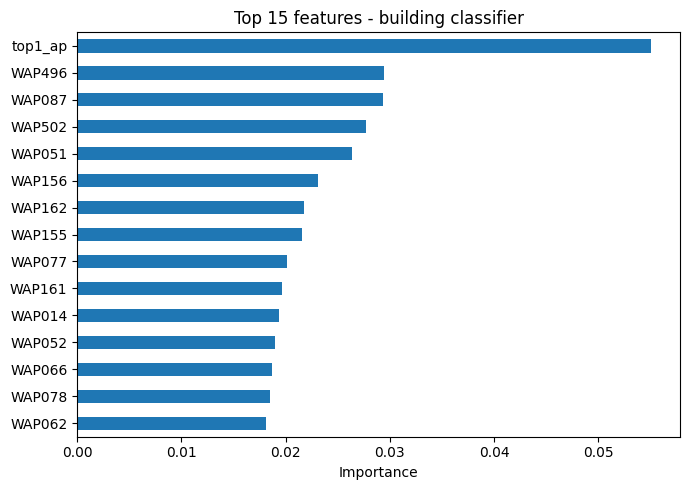

In [39]:
# Feature importance
import matplotlib.pyplot as plt

imp = pd.Series(final_models[0].feature_importances_, index=X_full.columns)
top15 = imp.sort_values(ascending=False).head(15)

top15.sort_values().plot(kind="barh", figsize=(7, 5))
plt.title("Top 15 features - building classifier")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig("building_feature_importance.png", dpi=150)
plt.show()

In [40]:
from google.colab import files

for f in ["predictions/building__ival.csv",
          "predictions/building_seed0__test.csv",
          "predictions/building_seed1__test.csv",
          "predictions/building_seed2__test.csv",
          "building_experiments.csv",
          "building_tuning.csv",
          "building_feature_importance.png",
          "features.py"]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>